# Calibrated Brillouin spectra: a measured-water experiment

This notebook actively reconstructs **all ten acquisition positions, two water frames each, and both ten-frame independent calibrations**. No cache-preview path supplies fresh values. The original standard-method reference is separately labeled; actual physical truth is unavailable. Water positions are acquisition indices, not a fabricated tissue image.

The method follows the camera-spectrum extraction, Lorentzian peak estimation, theoretical VIPA calibration and temporal interpolation in Schl??ler et al., *Biophysical Journal* (2018), DOI 10.1016/j.bpj.2018.07.027. The selected bmlab implementation is later Python software, with two independent standards rather than the historical article's methanol-only calibration. These measured-water example frames are not the paper's zebrafish specimens.


In [1]:
from pathlib import Path
import sys, json, time, hashlib, contextlib, io, subprocess, platform
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').exists()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import experiments,make_figures,relative_error
raw=load_data(ROOT/'data/raw_data.npz')
print({k:(v.shape,str(v.dtype)) for k,v in raw.items()})


{'images': ((1, 10, 2, 400, 400), 'uint16'), 'calibration_images': ((1, 2, 10, 400, 400), 'uint16'), 'calibration_time': ((1, 2), 'float64'), 'measurement_time': ((1, 10), 'float64'), 'exposure': ((1, 10), 'float64')}


## Physical model and implementation

In analysis-oriented row/column coordinates, a circular trace is $c+(R+d)e(\phi)$ with fitted center $c$, radius $R$, unit radial vector $e=(\cos\phi,\sin\phi)$ and offsets $d=-2,-1,0,1,2$ camera pixels. Average bilinear intensity samples over this strip at 500 uniformly spaced angles. Bright independent-calibration spots determine the circle. The same 64-edge boundary approximation as the original implementation sets trace endpoints.

The relative frequency is $f(p)=1/(a_0+a_1p+a_2p^2)-f_0$, where $p$ is arc-sample index, $a_0,a_1,a_2$ are dispersion coefficients and $f_0=c_0/\lambda_0$ is the laser frequency. Six reference-arm peaks constrain these coefficients and the free spectral range $F$ through known methanol/water shifts and adjacent interference orders. Calibration axes and geometry are interpolated in acquisition time; the unknown measured-water shifts never determine calibration.

Each spectral region uses $L(f)=B+A(\Gamma/2)^2/[(f-\mu)^2+(\Gamma/2)^2]$, with background $B$, height $A$, center $\mu$ and observed full width $\Gamma$. Two independent Brillouin regions and two Rayleigh regions are fitted for every frame. The final shift is the smallest absolute difference between each Brillouin center and either Rayleigh center.

The original spectral optimizer receives squared residuals, so the effective objective is $\frac12\sum(y-L)^4$. We preserve that choice and explicitly compare ordinary L2 specimen peak fitting below. VIPA calibration separately minimizes the sum of squared standard-frequency, symmetry and known-shift residuals with source Nelder?Mead defaults. Some fits reach their evaluation limit: the notebook reports the resulting independent calibration residual rather than implying exact convergence. Full initialization, units, objective residual groups and stopping rules are in the maintained approach plan.


In [2]:
start=time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()): fresh,details=reconstruct(raw)
reconstruction_runtime_s=time.perf_counter()-start
output=ROOT/'output/reconstruction.npz';output.parent.mkdir(exist_ok=True)
np.savez_compressed(output,**fresh)
reference=dict(np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False))
errors={k:relative_error(fresh[k],reference[k]) for k in fresh}
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(output),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,capture_output=True,text=True)
assert judged.returncode==0,(judged.stdout,judged.stderr)
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
assert report['status']=='pass'
print('Fresh full reconstruction runtime (s):',reconstruction_runtime_s)
print('Fresh versus independently executed original:')
print(json.dumps(errors,indent=2))
print('Independent Judge metrics:')
print(json.dumps(report['metrics'],indent=2))


D:\yan1\agent\AutoSkill\imaging-101-release\tasks\brillouin_water_spectral_shift\src\physics_model.py:218: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  opt_result = fmin(error, vipa_start, args=(peaks, setup.calibration.shifts))


Fresh full reconstruction runtime (s): 1.0778878999408334
Fresh versus independently executed original:
{
  "reconstruction": 0.0,
  "peak_parameters": 0.0,
  "frequency_axis": 0.0,
  "extracted_spectra": 0.0,
  "calibration_frequency": 0.0,
  "calibration_arcs": 0.0,
  "calibration_parameters": 0.0
}
Independent Judge metrics:
{
  "reconstruction": 0.0,
  "peak_parameters_component_0": 0.0,
  "peak_parameters_component_1": 0.0,
  "peak_parameters_component_2": 0.0,
  "peak_parameters_component_3": 0.0,
  "frequency_axis": 0.0,
  "extracted_spectra": 0.0,
  "calibration_frequency": 0.0,
  "calibration_arcs": 0.0,
  "calibration_parameters_component_0": 0.0,
  "calibration_parameters_component_1": 0.0,
  "calibration_parameters_component_2": 0.0,
  "calibration_parameters_component_3": 0.0
}


## Actively computed experiments

Recompute the complete camera/calibration pathway with 3- and 7-pixel radial strips instead of the standard 5-pixel strip. Also assign only the first calibration's frequency axis to all water frames while retaining interpolated extraction geometry; this isolates frequency-drift correction. Finally refine specimen peak parameters with an ordinary L2 objective, retaining the same independent standard calibration. These are fresh sensitivity variants, not substitutions for the original selected method.


In [3]:
start=time.perf_counter()
variants,source,measurements=experiments(raw,fresh,details)
experiment_runtime_s=time.perf_counter()-start
measurements.update(reconstruction_runtime_s=reconstruction_runtime_s,experiment_runtime_s=experiment_runtime_s,raw_data_sha256=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest(),upstream_relative_errors=errors,method='Fresh local camera-to-shift method and separately labeled variants',environment={'python':sys.version,'numpy':np.__version__,'platform':platform.platform()})
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2),encoding='utf8')
print(json.dumps(measurements,indent=2))
figures=make_figures(raw,fresh,details,reference,variants,source)
plt.close('all')


D:\yan1\agent\AutoSkill\imaging-101-release\tasks\brillouin_water_spectral_shift\src\physics_model.py:218: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  opt_result = fmin(error, vipa_start, args=(peaks, setup.calibration.shifts))
D:\yan1\agent\AutoSkill\imaging-101-release\tasks\brillouin_water_spectral_shift\src\physics_model.py:218: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  opt_result = fmin(error, vipa_start, args=(peaks, setup.calibration.shifts))
D:\yan1\agent\AutoSkill\imaging-101-release\tasks\brillouin_water_spectral_shift\src\physics_model.py:218: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  opt_result = fmin(error, vipa_start, args=(peaks, setup.calibration.shifts))
D:\yan1\agent\AutoSkill\imaging-101-release\tasks\brillouin_water_spectral_shift\src\physics_model.py:218: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  opt_result = fmin(error, vipa_start, 

{
  "upstream_objective": "quartic spectral residual, nonlinear VIPA sum-of-squares",
  "calibration_rms_MHz": 21.071759476417814,
  "calibration_max_abs_MHz": 44.3132555,
  "mean_shift_GHz": 5.024793697447883,
  "frame_and_region_std_MHz": 12.887793064388088,
  "variant_rms_change_MHz": {
    "width1": 5.819042494907294,
    "width3": 3.7938210724885524,
    "first_calibration": 2.483319369982709,
    "L2_peaks": 4.168502477453227
  },
  "reconstruction_runtime_s": 1.0778878999408334,
  "experiment_runtime_s": 4.980475600110367,
  "raw_data_sha256": "161b8f1acedbed5a7183ef93be1469b791bd9e3e6f69795205b9b9f244f7e47d",
  "upstream_relative_errors": {
    "reconstruction": 0.0,
    "peak_parameters": 0.0,
    "frequency_axis": 0.0,
    "extracted_spectra": 0.0,
    "calibration_frequency": 0.0,
    "calibration_arcs": 0.0,
    "calibration_parameters": 0.0
  },
  "method": "Fresh local camera-to-shift method and separately labeled variants",
  "environment": {
    "python": "3.11.11 (main

## Reconstruction and calibration

The image is an actual independent calibration mean, displayed with full intensity range and detector pixel centers. The curve is the freshly inferred circular centerline; green circles are detected spots. Both complete ten-frame calibration spectra and frequency axes are shown. Frequency ribbons span the actual calibration-frame minimum and maximum. The final water plot compares original and fresh region means; underscores and crosses mark the two separate camera frames. No curve is set to a nominal water shift.


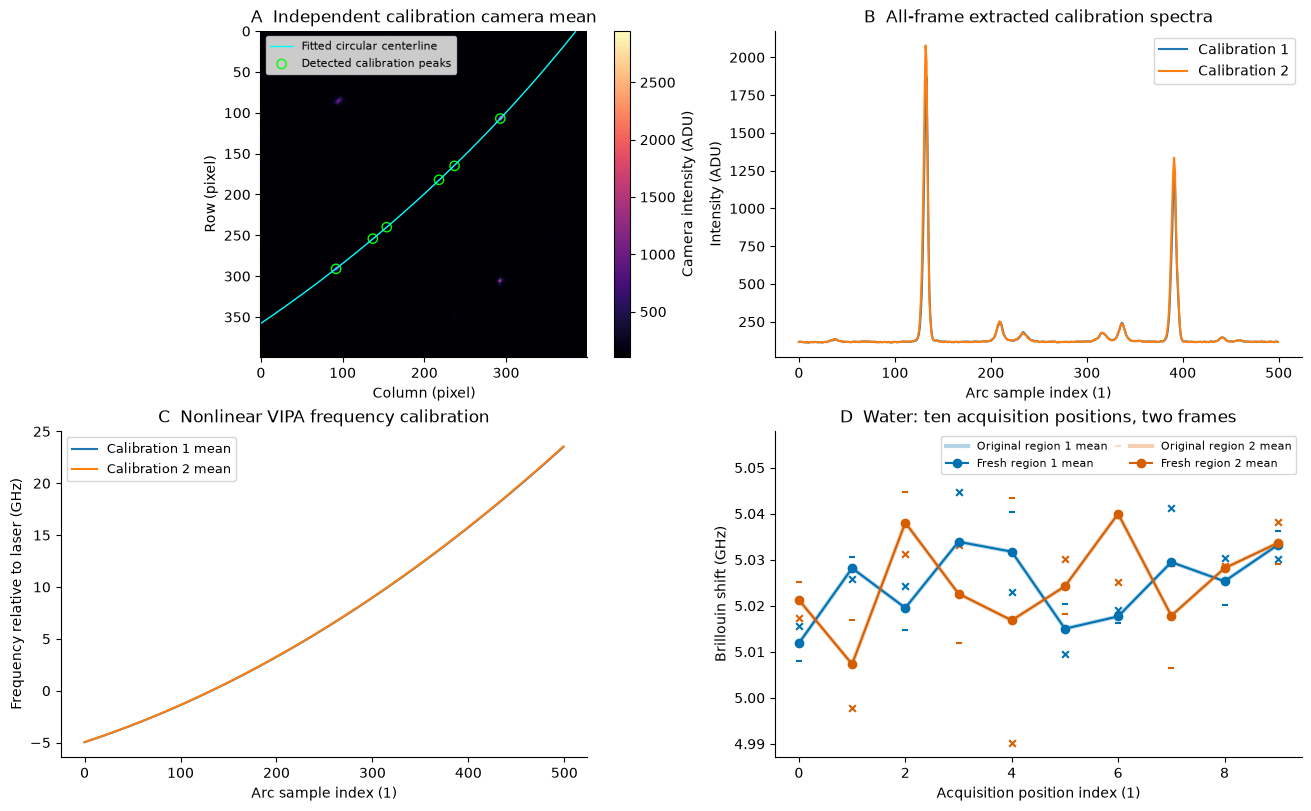

In [4]:
display(figures['reconstruction'])
plt.close(figures['reconstruction'])


## Forward residuals and sensitivity

All four modeled regions are overlaid on the full first-frame measured spectrum. Signed measured-minus-modeled residuals retain their natural ADU units and show the larger elastic-line shape mismatch. Shaded sensitivity bands are the minimum/maximum change across both frames and both Brillouin regions at each position, with the mean drawn as a line. The first-calibration experiment isolates the small time-dependent change induced by frequency-axis interpolation. Omitted spectral gaps have no fabricated fit values.


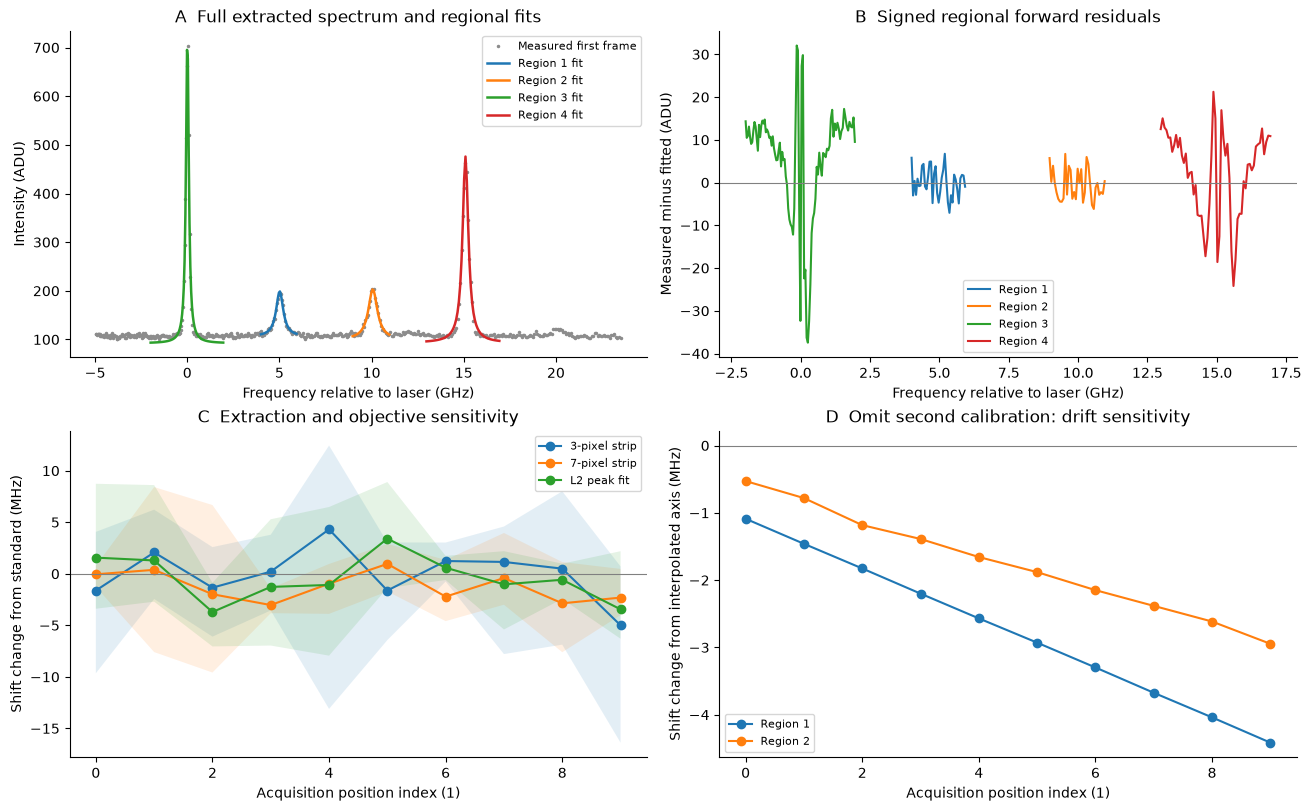

In [5]:
display(figures['robustness'])
plt.close(figures['robustness'])


## Independent physical diagnostics

Calibration residuals compare fitted dispersion at each measured calibration peak with that peak's **known independent standard frequency**. All twenty calibrator frames are plotted. The Stokes/anti-Stokes comparison exposes frame noise and region disagreement. All four observed Brillouin linewidth traces are shown; they include instrument broadening and do not measure intrinsic viscosity directly.


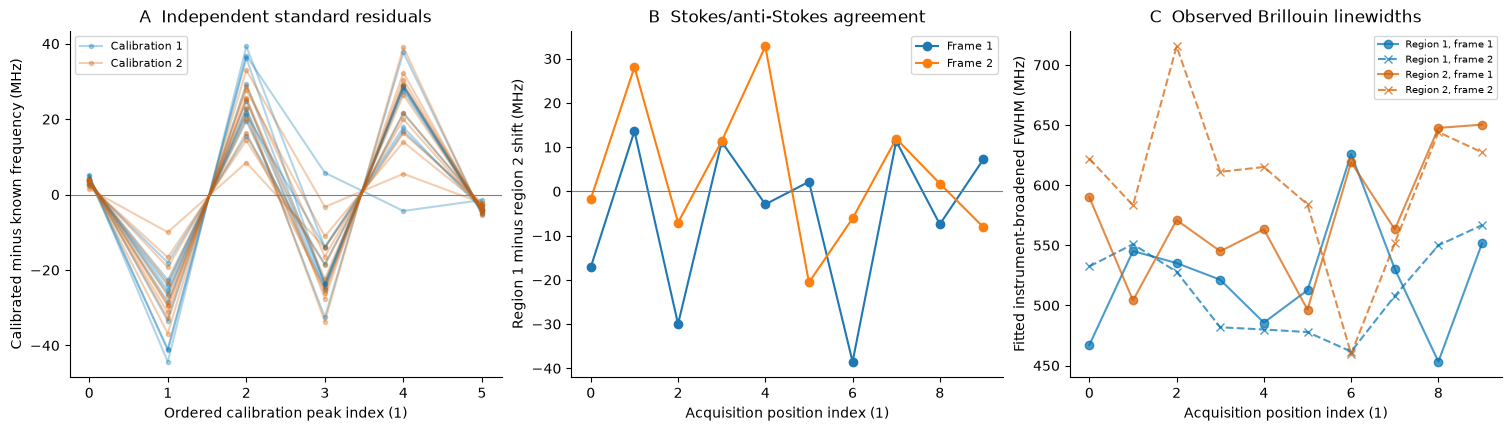

In [6]:
display(figures['physical_diagnostics'])
plt.close(figures['physical_diagnostics'])


## Interpretation and limitations

The source and fresh implementation agree numerically across every declared output, but that agreement does not remove calibration-model error. Independently known standard frequencies show a roughly 21 MHz RMS mismatch and up to 44 MHz residual. The complete measured-water mean is about 5.025 GHz with roughly 13 MHz spread across positions, frames and regions; it is not forced to the independent calibration standard's 5.066 GHz. Radial-strip, spectral-objective and calibration-time choices shift estimates by several MHz. These are useful instrument and analysis sensitivity measurements, not evidence of spatial tissue heterogeneity.

Some original VIPA fits stop at the default evaluation limit. The source quartic peak objective, polygon boundary approximation and algebraic circle fit are preserved and tested rather than silently replaced. Actual object truth and an independently measured instrument response are unavailable. The reference establishes standard-method reproduction; conclusions about absolute modulus, intrinsic linewidth or viscosity would require additional measurements.
